# Stanford Dogs: 10 ras

In [4]:
from pathlib import Path
import random

images_dir = Path("data/Images/Images")

10 pierwszych ras psów w kolejności losowej, mapowanie id - nazwa

In [5]:
random.seed(2718)
wszystkie_rasy = sorted([p for p in images_dir.iterdir() if p.is_dir()])
rasy_10 = sorted(random.sample(wszystkie_rasy, 10))

class_to_id = {r.name: i for i, r in enumerate(rasy_10)}
id_to_class = {i: n for n, i in class_to_id.items()}

# split tylko na pierwszym "-" z myślą o Shih-Tzu
def ladna_nazwa(folder):
    return folder.split("-", 1)[-1]

for nazwa, i in class_to_id.items():
    print(i, ladna_nazwa(nazwa), f"({nazwa})")

0 Chihuahua (n02085620-Chihuahua)
1 Japanese_spaniel (n02085782-Japanese_spaniel)
2 black-and-tan_coonhound (n02089078-black-and-tan_coonhound)
3 Scottish_deerhound (n02092002-Scottish_deerhound)
4 Weimaraner (n02092339-Weimaraner)
5 Norfolk_terrier (n02094114-Norfolk_terrier)
6 Airedale (n02096051-Airedale)
7 Australian_terrier (n02096294-Australian_terrier)
8 German_shepherd (n02106662-German_shepherd)
9 African_hunting_dog (n02116738-African_hunting_dog)


Lista - ścieżka i label

In [6]:
samples = []
for rasa in rasy_10:
    label = class_to_id[rasa.name]
    for f in sorted(rasa.iterdir()):
        if f.suffix.lower() in (".jpg", ".jpeg"):
            samples.append((f, label))

print("Liczba zdjęć:", len(samples))
assert 100 <= len(samples) <= 10000, "Liczba zdjęć poza oczekiwanym zakresem"

Liczba zdjęć: 1779


Kontrola liczności klas

In [7]:
from collections import Counter

licznik = Counter(label for _, label in samples)
for i in range(len(rasy_10)):
    print(i, ladna_nazwa(id_to_class[i]), licznik[i])

print(samples[:3])

0 Chihuahua 152
1 Japanese_spaniel 185
2 black-and-tan_coonhound 159
3 Scottish_deerhound 232
4 Weimaraner 160
5 Norfolk_terrier 172
6 Airedale 202
7 Australian_terrier 196
8 German_shepherd 152
9 African_hunting_dog 169
[(PosixPath('data/Images/Images/n02085620-Chihuahua/n02085620_10074.jpg'), 0), (PosixPath('data/Images/Images/n02085620-Chihuahua/n02085620_10131.jpg'), 0), (PosixPath('data/Images/Images/n02085620-Chihuahua/n02085620_10621.jpg'), 0)]


Podział, 80 - train, 10 - test, 10 - walidacja

In [8]:
from sklearn.model_selection import train_test_split

SEED = 2718

labels = [label for _, label in samples]

train_samples, tmp_samples = train_test_split(
    samples,
    test_size=0.2,
    stratify=labels,
    random_state=SEED,
    shuffle=True,
)

tmp_labels = [label for _, label in tmp_samples]
val_samples, test_samples = train_test_split(
    tmp_samples,
    test_size=0.5,
    stratify=tmp_labels,
    random_state=SEED,
    shuffle=True,
)

print("train:", len(train_samples))
print("val:  ", len(val_samples))
print("test: ", len(test_samples))

train: 1423
val:   178
test:  178


Kontrola przecieku

In [9]:
paths_train = set(p for p, _ in train_samples)
paths_val = set(p for p, _ in val_samples)
paths_test = set(p for p, _ in test_samples)

assert not paths_train & paths_val
assert not paths_train & paths_test
assert not paths_val & paths_test
assert len(train_samples) + len(val_samples) + len(test_samples) == len(samples)

cnt_train = Counter(label for _, label in train_samples)
cnt_val = Counter(label for _, label in val_samples)
cnt_test = Counter(label for _, label in test_samples)

for i in range(len(rasy_10)):
    print(i, ladna_nazwa(id_to_class[i]),
          "train:", cnt_train[i], "val:", cnt_val[i], "test:", cnt_test[i])

0 Chihuahua train: 122 val: 15 test: 15
1 Japanese_spaniel train: 148 val: 18 test: 19
2 black-and-tan_coonhound train: 127 val: 16 test: 16
3 Scottish_deerhound train: 185 val: 23 test: 24
4 Weimaraner train: 128 val: 16 test: 16
5 Norfolk_terrier train: 138 val: 17 test: 17
6 Airedale train: 161 val: 21 test: 20
7 Australian_terrier train: 157 val: 20 test: 19
8 German_shepherd train: 122 val: 15 test: 15
9 African_hunting_dog train: 135 val: 17 test: 17


Dataset i transformacje

In [10]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

SEED = 2718
torch.manual_seed(SEED)

# normalizacja na ImageNet
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

tfm = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class DogsDataset(Dataset):
    def __init__(self, samples, transform=None):
        self.samples = samples          # lista (ścieżka, label)
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert("RGB")   # część zdjęć może nie być RGB
        if self.transform:
            img = self.transform(img)
        return img, label

train_ds = DogsDataset(train_samples, tfm)
val_ds = DogsDataset(val_samples, tfm)
test_ds = DogsDataset(test_samples, tfm)

Dataloadery

In [11]:
BATCH_SIZE = 32

g = torch.Generator().manual_seed(SEED)   # stała kolejność tasowania po każdym uruchomieniu

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          generator=g, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

images, labels = next(iter(train_loader))
print("images.shape:", images.shape)
print("labels[:8]:", labels[:8])

images.shape: torch.Size([32, 3, 224, 224])
labels[:8]: tensor([5, 7, 1, 3, 7, 4, 6, 4])


Obrazki z batcha z etykietami i zapis do pliku

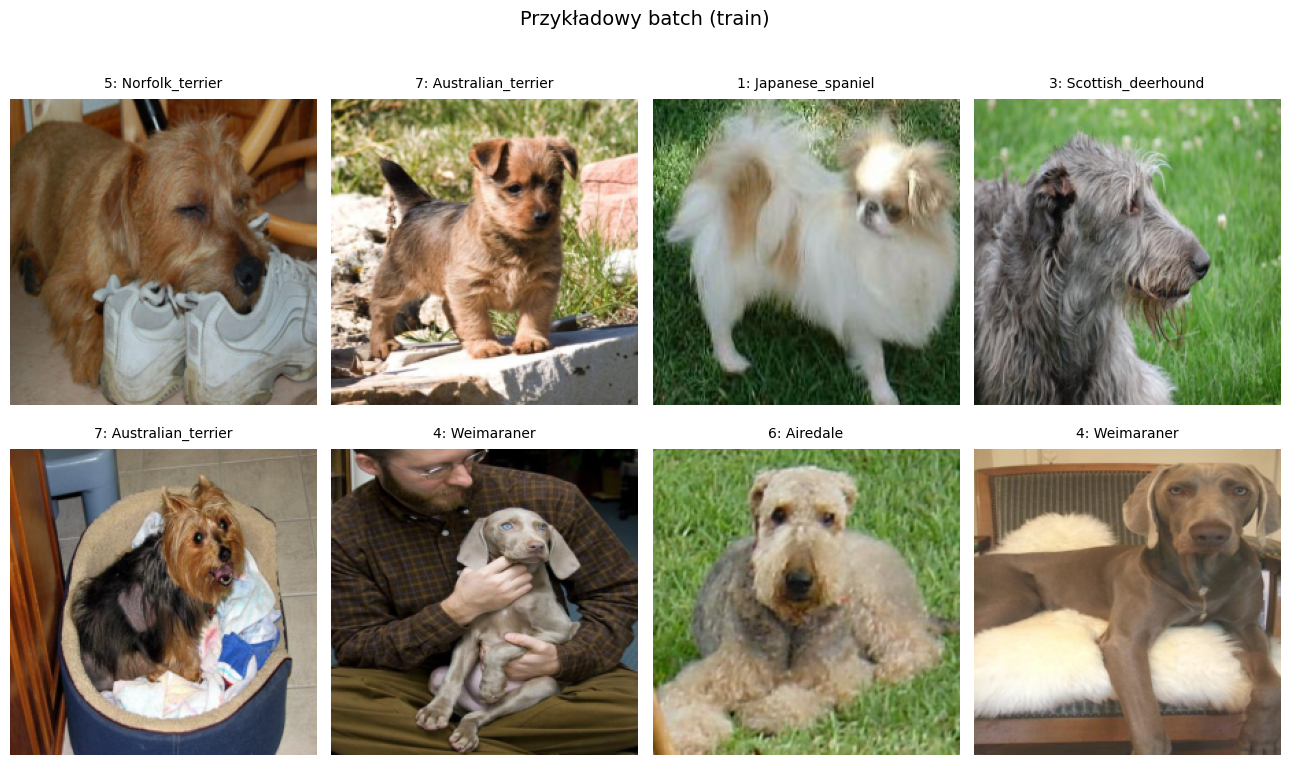

In [13]:
import matplotlib.pyplot as plt

plots_dir = Path("plots")
mean = torch.tensor(MEAN).view(3, 1, 1)
std = torch.tensor(STD).view(3, 1, 1)

n = 8
fig, axes = plt.subplots(2, 4, figsize=(13, 8))
for ax, img, lab in zip(axes.flat, images[:n], labels[:n]):
    img = (img * std + mean).clamp(0, 1)
    ax.imshow(img.permute(1, 2, 0).numpy())
    ax.set_title(f"{lab.item()}: {ladna_nazwa(id_to_class[lab.item()])}",
                 fontsize=10, pad=8)
    ax.axis("off")

fig.suptitle("Przykładowy batch (train)", fontsize=14)
plt.tight_layout(h_pad=2.5, rect=[0, 0, 1, 0.96])   # odstęp między rzędami + miejsce na tytuł główny
plt.savefig(plots_dir / "batch_przyklady.png", dpi=150, bbox_inches="tight")
plt.show()